## Accepted Pickup Tasks During One Workday (Flag 13)

### Dataset Overview

A continuous workday trajectory linked to 32 accepted pickup tasks with acceptance times, completion times, and pickup locations. Road reconstruction: 1573 GPS points along the archived local OSM street network, with all road vertices retained and irregular moving intervals bounded by 45 m. Oneway tags are respected; turn-restriction relations are not modeled. Times are local Shanghai time; speed_kmh and activity_state describe the preceding segment. Task events and AOI locations are constructed, not authentic observations. All 32 task records have task_type=pickup; no delivery tasks are included. A pause in pickup completions does not identify what other activity, if any, took place. Nearby means within 1 km in both proximity-priority and pause analyses; older farther tasks are at least 0.25 km farther at the same comparison time.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Analyze the courier's accepted pickup workload, completion priorities, and pauses during the observed workday.

Role: Last-mile pickup operations analyst


Category: pending workload, spatial pickup priority, and completion pauses


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "pickup_tasks.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does the pending pickup workload change as tasks are accepted and completed?

#### Analysis action

Reconstruct pending counts at each minute from acceptance and pickup timestamps, then inspect the event flow.

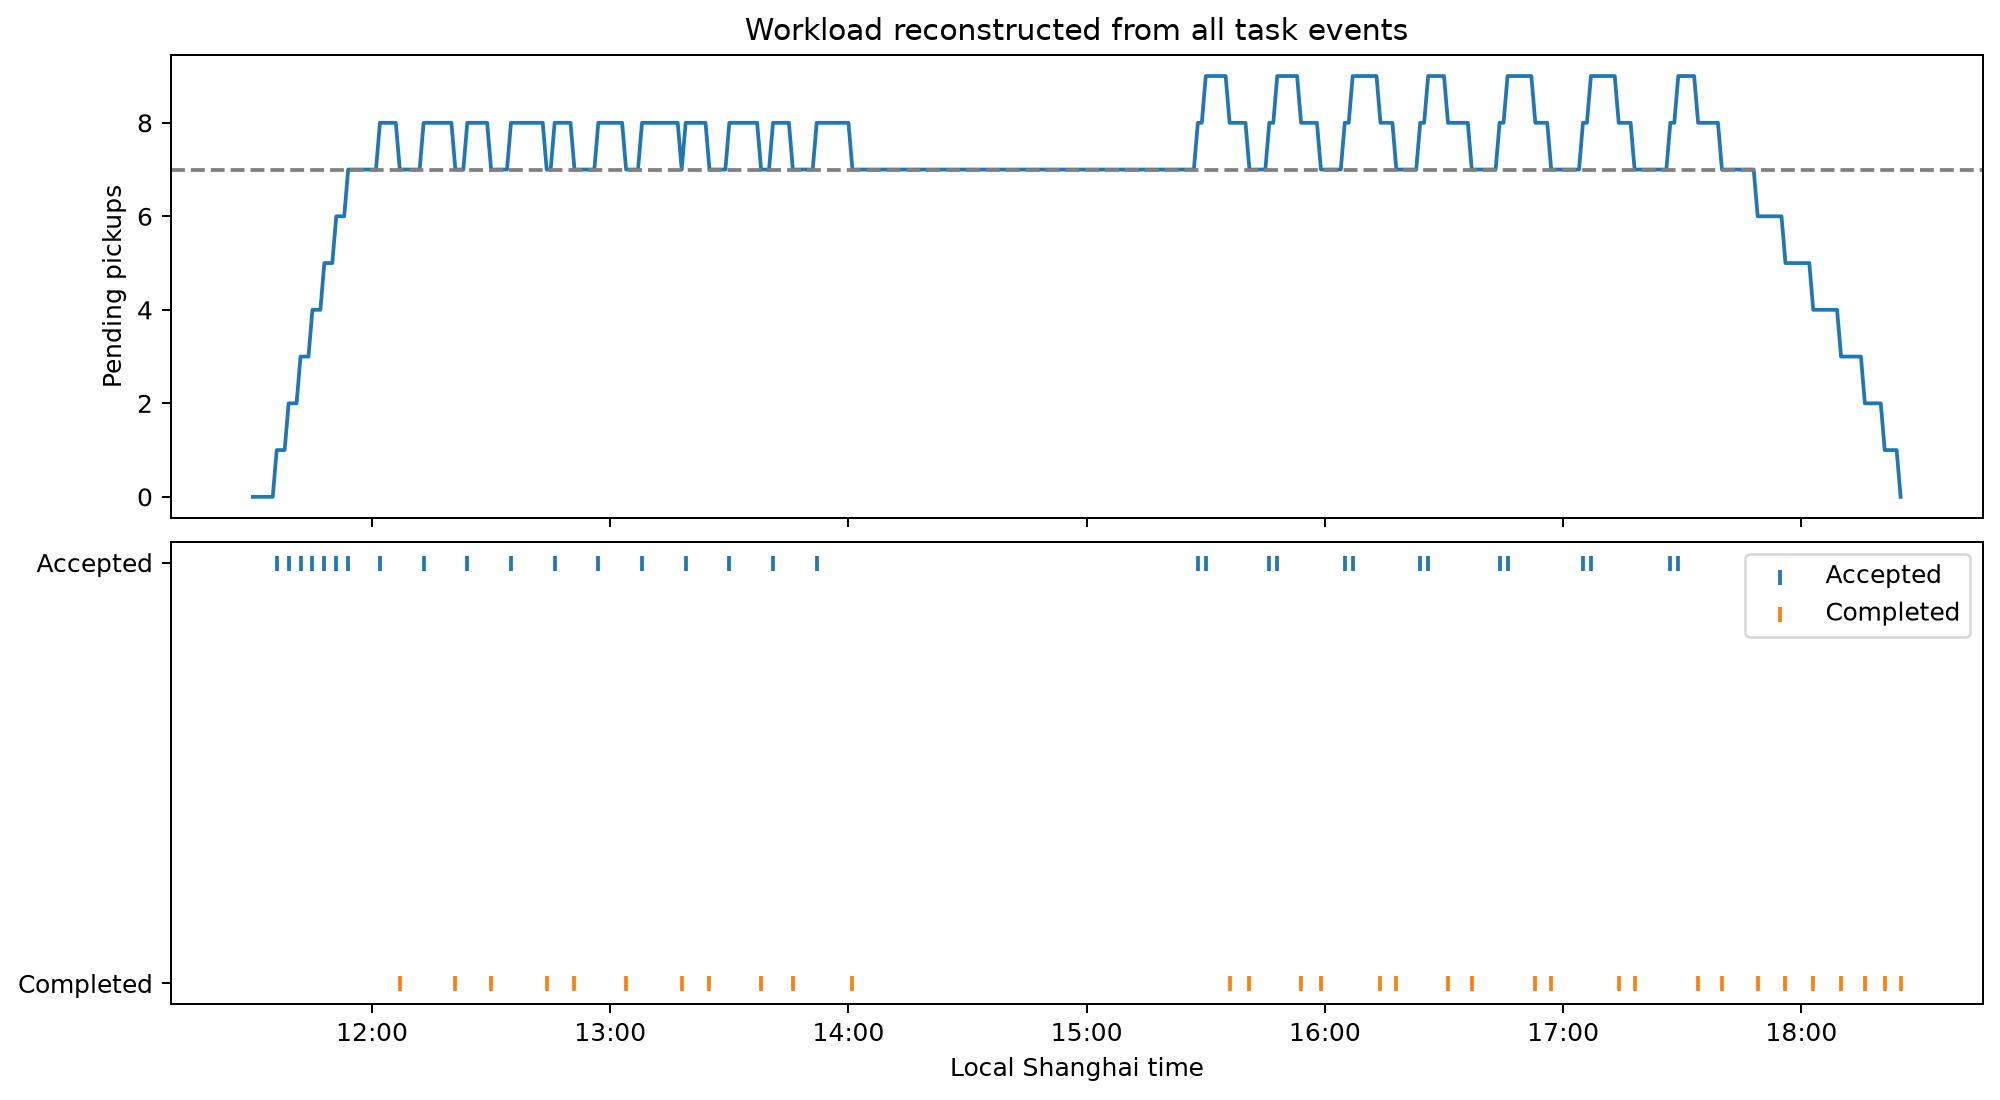

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def pending_timeline(df, user_df):
    import matplotlib.dates as mdates

    d = df.copy()
    d.accept_time = pd.to_datetime(d.accept_time)
    d.pickup_time = pd.to_datetime(d.pickup_time)
    times = pd.date_range(
        pd.Timestamp(user_df.gps_time.iloc[0]),
        pd.Timestamp(user_df.gps_time.iloc[-1]),
        freq="1min",
    )
    pending = np.array(
        [((d.accept_time <= t) & (d.pickup_time > t)).sum() for t in times]
    )
    fig, axes = plt.subplots(
        2, 1, figsize=(11, 6), sharex=True, constrained_layout=True
    )
    axes[0].plot(times, pending)
    axes[0].axhline(7, color="gray", ls="--")
    axes[0].set(
        ylabel="Pending pickups", title="Workload reconstructed from all task events"
    )
    axes[1].scatter(d.accept_time, np.ones(len(d)), marker="|", label="Accepted")
    axes[1].scatter(d.pickup_time, np.zeros(len(d)), marker="|", label="Completed")
    axes[1].set(
        yticks=[0, 1],
        yticklabels=["Completed", "Accepted"],
        xlabel="Local Shanghai time",
    )
    axes[1].legend()
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    active = times >= pd.Timestamp("2026-07-10 12:00:00")
    return {
        "modal_afternoon_pending": int(pd.Series(pending[active]).mode().iloc[0]),
        "afternoon_share_between_6_and_9": float(
            ((pending[active] >= 6) & (pending[active] <= 9)).mean()
        ),
    }


evidence = pending_timeline(df, user_df)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/pending_pickup_timeline.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "pickup_acceptance_completion_timeline",
  "insight_type": "overall_pattern",
  "insight": "The number of pending pickups stays roughly stable through much of the afternoon, despite frequent task acceptances and completions.",
  "insight_value": {
    "modal_afternoon_pending": 7,
    "afternoon_share_between_6_and_9": 0.9222797927461139
  },
  "plot": {
    "plot_type": "pending_count_and_event_timeline",
    "title": "Pending Pickup Workload",
    "file": "visualizations/pending_pickup_timeline.png",
    "description": "Recomputed from the delivered CSVs; road geometry preserves mapped vertices."
  },
  "question": "How does the pending pickup workload change as tasks are accepted and completed?",
  "actionable_insight": "Reconstruct pending counts at each minute from acceptance and pickup timestamps, then inspect the event flow.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\n\ndef pending_timeline(df,user_df):\n    import matplotlib.dates as mdates\n    d=df.copy();d.accept_time=pd.to_datetime(d.accept_time);d.pickup_time=pd.to_datetime(d.pickup_time)\n    times=pd.date_range(pd.Timestamp(user_df.gps_time.iloc[0]),pd.Timestamp(user_df.gps_time.iloc[-1]),freq='1min')\n    pending=np.array([((d.accept_time<=t)&(d.pickup_time>t)).sum() for t in times])\n    fig,axes=plt.subplots(2,1,figsize=(11,6),sharex=True,constrained_layout=True)\n    axes[0].plot(times,pending);axes[0].axhline(7,color='gray',ls='--');axes[0].set(ylabel='Pending pickups',title='Workload reconstructed from all task events')\n    axes[1].scatter(d.accept_time,np.ones(len(d)),marker='|',label='Accepted');axes[1].scatter(d.pickup_time,np.zeros(len(d)),marker='|',label='Completed')\n    axes[1].set(yticks=[0,1],yticklabels=['Completed','Accepted'],xlabel='Local Shanghai time');axes[1].legend()\n    axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))\n    active=times>=pd.Timestamp('2026-07-10 12:00:00')\n    return {'modal_afternoon_pending':int(pd.Series(pending[active]).mode().iloc[0]),'afternoon_share_between_6_and_9':float(((pending[active]>=6)&(pending[active]<=9)).mean())}\n\nevidence=pending_timeline(df,user_df)\nprint(evidence)\nplt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "pickup_time",
    "task_id"
  ]
}

### **Question 2**: Are newly accepted nearby tasks sometimes completed before older tasks that were farther away?

#### Analysis action

Compare acceptance distance, task age, and pickup completion order rather than acceptance order alone.

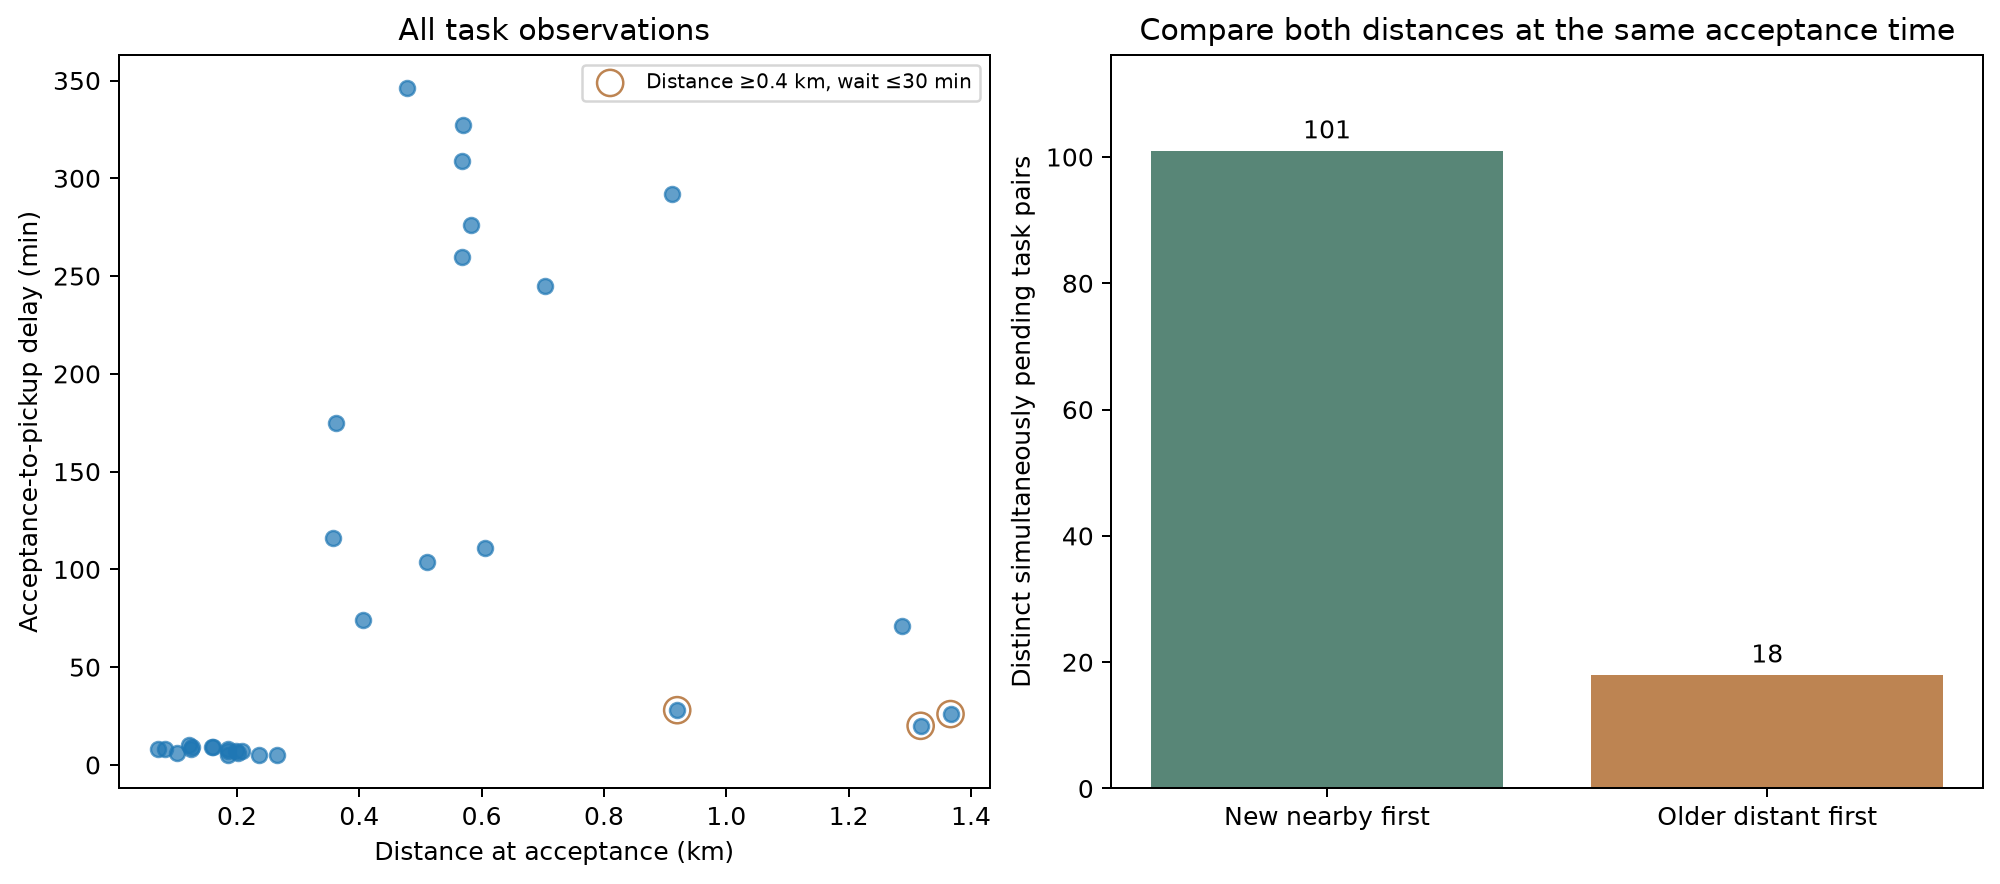

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def close_task_priority(df, user_df):
    d = df.copy()
    d.accept_time = pd.to_datetime(d.accept_time)
    d.pickup_time = pd.to_datetime(d.pickup_time)
    stamps = pd.to_datetime(user_df.gps_time, format="mixed").astype("int64").to_numpy()
    origin = stamps[0]
    stamps = stamps - origin
    pairs = []
    # Define proximity before observing completion order; selecting only quick
    # completions here would bias the result toward "new nearby first".
    for new in d.itertuples():
        moment = new.accept_time.value - origin
        pos = np.array(
            [
                np.interp(moment, stamps, user_df.lng),
                np.interp(moment, stamps, user_df.lat),
            ]
        )
        near = np.linalg.norm(
            (np.array([new.pickup_lng, new.pickup_lat]) - pos) * [95.2, 111]
        )
        for old in d[
            (d.accept_time < new.accept_time) & (d.pickup_time > new.accept_time)
        ].itertuples():
            far = np.linalg.norm(
                (np.array([old.pickup_lng, old.pickup_lat]) - pos) * [95.2, 111]
            )
            if far > near + 0.25 and near < 1.0:
                pairs.append(
                    {
                        "new_task": new.pickup_task_id,
                        "older_task": old.pickup_task_id,
                        "new_distance_km": float(near),
                        "old_distance_km": float(far),
                        "new_first": bool(new.pickup_time < old.pickup_time),
                    }
                )
    pairs = pd.DataFrame(pairs)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
    axes[0].scatter(
        d.distance_from_courier_at_accept_km, d.wait_after_accept_min, alpha=0.7
    )
    exceptions = d[
        d.distance_from_courier_at_accept_km.ge(0.4) & d.wait_after_accept_min.le(30)
    ]
    axes[0].scatter(
        exceptions.distance_from_courier_at_accept_km,
        exceptions.wait_after_accept_min,
        facecolors="none",
        edgecolors="#bd8452",
        s=110,
        label="Distance ≥0.4 km, wait ≤30 min",
    )
    axes[0].legend(fontsize=8)
    axes[0].set(
        xlabel="Distance at acceptance (km)",
        ylabel="Acceptance-to-pickup delay (min)",
        title="All task observations",
    )
    counts = pairs.new_first.value_counts().reindex([True, False], fill_value=0)
    axes[1].bar(
        ["New nearby first", "Older distant first"],
        counts,
        color=["#588677", "#bd8452"],
    )
    for x, count in enumerate(counts):
        axes[1].text(x, count + 1, str(int(count)), ha="center", va="bottom")
    axes[1].set_ylim(0, max(counts) * 1.15)
    axes[1].set(
        ylabel="Distinct simultaneously pending task pairs",
        title="Compare both distances at the same acceptance time",
    )
    return {
        "distinct_pairs": len(pairs),
        "new_tasks_with_comparisons": pairs.new_task.nunique(),
        "new_nearby_completed_first_share": float(pairs.new_first.mean()),
        "older_distant_completed_first_pairs": int((~pairs.new_first).sum()),
        "counterexample_pairs": (
            pairs.loc[~pairs.new_first, ["new_task", "older_task"]].to_dict("records")
        ),
        "farther_quick_pickups": int(len(exceptions)),
        "close_long_wait_pickups": int(
            (
                d.distance_from_courier_at_accept_km.lt(0.4)
                & d.wait_after_accept_min.gt(30)
            ).sum()
        ),
        "nearby_radius_km": 1.0,
        "selection_rule": (
            "All accepted pickup tasks; nearby <1.0 km and older pending task at least"
            " 0.25 km farther at the same acceptance time. No completion-delay"
            " prefilter. The same 1 km nearby radius is used for the completion pause."
        ),
    }


evidence = close_task_priority(df, user_df)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/new_close_before_old_distant.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "acceptance_distance_and_pickup_priority",
  "insight_type": "factor_relationship",
  "insight": "Newly accepted tasks close to the courier are often completed before older, more distant tasks.",
  "insight_value": {
    "distinct_pairs": 119,
    "new_tasks_with_comparisons": 25,
    "new_nearby_completed_first_share": 0.8487394957983193,
    "older_distant_completed_first_pairs": 18,
    "counterexample_pairs": [
      {
        "new_task": "P13_005",
        "older_task": "P13_004"
      },
      {
        "new_task": "P13_006",
        "older_task": "P13_004"
      },
      {
        "new_task": "P13_007",
        "older_task": "P13_004"
      },
      {
        "new_task": "P13_022",
        "older_task": "P13_003"
      },
      {
        "new_task": "P13_022",
        "older_task": "P13_006"
      },
      {
        "new_task": "P13_024",
        "older_task": "P13_003"
      },
      {
        "new_task": "P13_024",
        "older_task": "P13_004"
      },
      {
        "new_task": "P13_024",
        "older_task": "P13_006"
      },
      {
        "new_task": "P13_026",
        "older_task": "P13_004"
      },
      {
        "new_task": "P13_026",
        "older_task": "P13_005"
      },
      {
        "new_task": "P13_026",
        "older_task": "P13_006"
      },
      {
        "new_task": "P13_026",
        "older_task": "P13_007"
      },
      {
        "new_task": "P13_026",
        "older_task": "P13_024"
      },
      {
        "new_task": "P13_030",
        "older_task": "P13_006"
      },
      {
        "new_task": "P13_030",
        "older_task": "P13_026"
      },
      {
        "new_task": "P13_030",
        "older_task": "P13_028"
      },
      {
        "new_task": "P13_032",
        "older_task": "P13_001"
      },
      {
        "new_task": "P13_032",
        "older_task": "P13_004"
      }
    ],
    "farther_quick_pickups": 3,
    "close_long_wait_pickups": 2,
    "nearby_radius_km": 1.0,
    "selection_rule": "All accepted pickup tasks; nearby <1.0 km and older pending task at least 0.25 km farther at the same acceptance time. No completion-delay prefilter. The same 1 km nearby radius is used for the completion pause."
  },
  "plot": {
    "plot_type": "distance_wait_scatter_and_completion_pairs",
    "title": "Distance-sensitive Pickup Priority",
    "file": "visualizations/new_close_before_old_distant.png",
    "description": "All task observations and simultaneous-pending pair comparisons, without preselecting fast completions; the reverse-order count is explicitly displayed."
  },
  "question": "Are newly accepted nearby tasks sometimes completed before older tasks that were farther away?",
  "actionable_insight": "Compare acceptance distance, task age, and pickup completion order rather than acceptance order alone.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\n\ndef close_task_priority(df,user_df):\n    d=df.copy();d.accept_time=pd.to_datetime(d.accept_time);d.pickup_time=pd.to_datetime(d.pickup_time)\n    stamps=pd.to_datetime(user_df.gps_time,format='mixed').astype('int64').to_numpy();origin=stamps[0];stamps=stamps-origin\n    pairs=[]\n    # Define proximity before observing completion order; selecting only quick\n    # completions here would bias the result toward \"new nearby first\".\n    for new in d.itertuples():\n        moment=new.accept_time.value-origin;pos=np.array([np.interp(moment,stamps,user_df.lng),np.interp(moment,stamps,user_df.lat)])\n        near=np.linalg.norm((np.array([new.pickup_lng,new.pickup_lat])-pos)*[95.2,111])\n        for old in d[(d.accept_time<new.accept_time)&(d.pickup_time>new.accept_time)].itertuples():\n            far=np.linalg.norm((np.array([old.pickup_lng,old.pickup_lat])-pos)*[95.2,111])\n            if far>near+.25 and near<1.0:\n                pairs.append({'new_task':new.pickup_task_id,'older_task':old.pickup_task_id,'new_distance_km':float(near),'old_distance_km':float(far),'new_first':bool(new.pickup_time<old.pickup_time)})\n    pairs=pd.DataFrame(pairs)\n    fig,axes=plt.subplots(1,2,figsize=(11,4.8),constrained_layout=True)\n    axes[0].scatter(d.distance_from_courier_at_accept_km,d.wait_after_accept_min,alpha=.7)\n    exceptions=d[d.distance_from_courier_at_accept_km.ge(.4)&d.wait_after_accept_min.le(30)]\n    axes[0].scatter(exceptions.distance_from_courier_at_accept_km,exceptions.wait_after_accept_min,\n        facecolors='none',edgecolors='#bd8452',s=110,label='Distance ≥0.4 km, wait ≤30 min')\n    axes[0].legend(fontsize=8)\n    axes[0].set(xlabel='Distance at acceptance (km)',ylabel='Acceptance-to-pickup delay (min)',title='All task observations')\n    counts=pairs.new_first.value_counts().reindex([True,False],fill_value=0)\n    axes[1].bar(['New nearby first','Older distant first'],counts,color=['#588677','#bd8452'])\n    for x, count in enumerate(counts):\n        axes[1].text(x, count+1, str(int(count)), ha='center', va='bottom')\n    axes[1].set_ylim(0, max(counts)*1.15)\n    axes[1].set(ylabel='Distinct simultaneously pending task pairs',title='Compare both distances at the same acceptance time')\n    return {'distinct_pairs':len(pairs),'new_tasks_with_comparisons':pairs.new_task.nunique(),\n            'new_nearby_completed_first_share':float(pairs.new_first.mean()),\n            'older_distant_completed_first_pairs':int((~pairs.new_first).sum()),\n            'counterexample_pairs':pairs.loc[~pairs.new_first,['new_task','older_task']].to_dict('records'),\n            'farther_quick_pickups':int(len(exceptions)),\n            'close_long_wait_pickups':int((d.distance_from_courier_at_accept_km.lt(.4)&d.wait_after_accept_min.gt(30)).sum()),\n            'nearby_radius_km':1.0,\n            'selection_rule':'All accepted pickup tasks; nearby <1.0 km and older pending task at least 0.25 km farther at the same acceptance time. No completion-delay prefilter. The same 1 km nearby radius is used for the completion pause.'}\n\nevidence=close_task_priority(df,user_df)\nprint(evidence)\nplt.show()",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "pickup_time",
    "gps_position",
    "gps_time",
    "courier_id",
    "task_id"
  ]
}

### **Question 3**: Is there a prolonged interval with no pickup completions even though accepted tasks remain nearby?

#### Analysis action

Find the longest gap between pickup completions, count tasks pending throughout it, and map their locations against the courier trajectory.

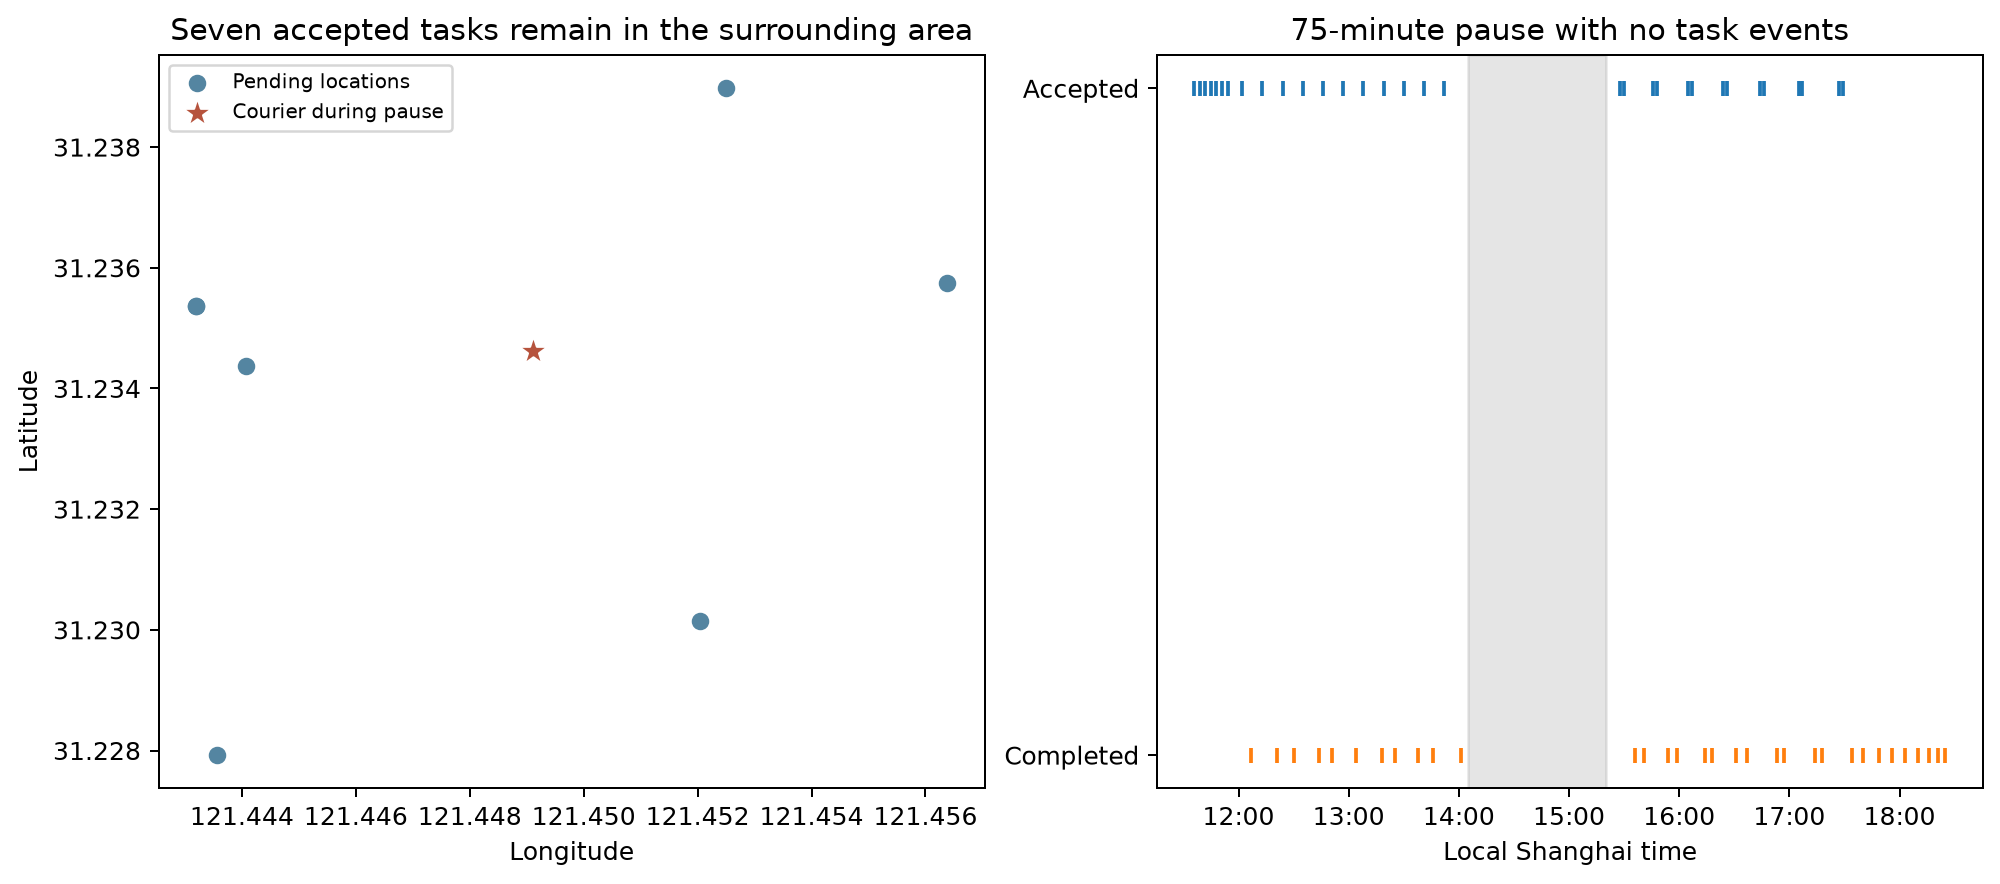

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def completion_pause(df, user_df):
    import matplotlib.dates as mdates

    start = pd.Timestamp("2026-07-10 14:05:00")
    end = pd.Timestamp("2026-07-10 15:20:00")
    d = df.copy()
    d.accept_time = pd.to_datetime(d.accept_time)
    d.pickup_time = pd.to_datetime(d.pickup_time)
    pending = d[(d.accept_time <= start) & (d.pickup_time > end)]
    stamps = pd.to_datetime(user_df.gps_time, format="mixed")
    q = user_df[(stamps >= start) & (stamps <= end)]
    center = q[["lng", "lat"]].mean().to_numpy()
    distance = np.linalg.norm(
        (pending[["pickup_lng", "pickup_lat"]].to_numpy() - center) * [95.2, 111],
        axis=1,
    )
    assert (distance < 1.0).all()
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
    axes[0].scatter(
        pending.pickup_lng,
        pending.pickup_lat,
        label="Pending locations",
        color="#5485a1",
    )
    axes[0].scatter(
        [center[0]],
        [center[1]],
        marker="*",
        s=160,
        color="#b6533d",
        edgecolors="white",
        zorder=5,
        label="Courier during pause",
    )
    axes[0].set(
        xlabel="Longitude",
        ylabel="Latitude",
        title="Seven accepted tasks remain in the surrounding area",
    )
    axes[0].legend(fontsize=8)
    axes[0].ticklabel_format(useOffset=False)
    axes[1].scatter(d.accept_time, np.ones(len(d)), marker="|", label="Accepted")
    axes[1].scatter(d.pickup_time, np.zeros(len(d)), marker="|", label="Completed")
    axes[1].axvspan(start, end, alpha=0.2, color="gray")
    axes[1].set(
        yticks=[0, 1],
        yticklabels=["Completed", "Accepted"],
        xlabel="Local Shanghai time",
        title="75-minute pause with no task events",
    )
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    return {
        "pause_start": str(start),
        "pause_end": str(end),
        "pause_minutes": 75,
        "pending_throughout_pause": len(pending),
        "nearby_radius_km": 1.0,
        "pending_distance_min_km": float(distance.min()),
        "pending_distance_max_km": float(distance.max()),
        "acceptances_during_pause": int(d.accept_time.between(start, end).sum()),
        "completions_during_pause": int(d.pickup_time.between(start, end).sum()),
    }


evidence = completion_pause(df, user_df)
print(evidence)
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/pickup_completion_pause.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "pickup_completion_pause_with_pending_locations",
  "insight_type": "exception_deviation",
  "insight": "A prolonged pause in pickup completions occurs while several accepted tasks remain near the courier.",
  "insight_value": {
    "pause_start": "2026-07-10 14:05:00",
    "pause_end": "2026-07-10 15:20:00",
    "pause_minutes": 75,
    "pending_throughout_pause": 7,
    "nearby_radius_km": 1.0,
    "pending_distance_min_km": 0.47938006162936964,
    "pending_distance_max_km": 0.9107933692063442,
    "acceptances_during_pause": 0,
    "completions_during_pause": 0
  },
  "plot": {
    "plot_type": "pause_map_and_event_rate",
    "title": "Pickup Completion Pause",
    "file": "visualizations/pickup_completion_pause.png",
    "description": "Recomputed from the delivered CSVs; road geometry preserves mapped vertices."
  },
  "question": "Is there a prolonged interval with no pickup completions even though accepted tasks remain nearby?",
  "actionable_insight": "Find the longest gap between pickup completions, count tasks pending throughout it, and map their locations against the courier trajectory.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\n\ndef completion_pause(df,user_df):\n    import matplotlib.dates as mdates\n    start=pd.Timestamp('2026-07-10 14:05:00');end=pd.Timestamp('2026-07-10 15:20:00')\n    d=df.copy();d.accept_time=pd.to_datetime(d.accept_time);d.pickup_time=pd.to_datetime(d.pickup_time)\n    pending=d[(d.accept_time<=start)&(d.pickup_time>end)]\n    stamps=pd.to_datetime(user_df.gps_time,format='mixed');q=user_df[(stamps>=start)&(stamps<=end)]\n    center=q[['lng','lat']].mean().to_numpy();distance=np.linalg.norm((pending[['pickup_lng','pickup_lat']].to_numpy()-center)*[95.2,111],axis=1)\n    assert (distance<1.0).all()\n    fig,axes=plt.subplots(1,2,figsize=(11,4.8),constrained_layout=True)\n    axes[0].scatter(pending.pickup_lng,pending.pickup_lat,label='Pending locations',color='#5485a1')\n    axes[0].scatter([center[0]],[center[1]],marker='*',s=160,color='#b6533d',edgecolors='white',zorder=5,label='Courier during pause')\n    axes[0].set(xlabel='Longitude',ylabel='Latitude',title='Seven accepted tasks remain in the surrounding area');axes[0].legend(fontsize=8);axes[0].ticklabel_format(useOffset=False)\n    axes[1].scatter(d.accept_time,np.ones(len(d)),marker='|',label='Accepted');axes[1].scatter(d.pickup_time,np.zeros(len(d)),marker='|',label='Completed')\n    axes[1].axvspan(start,end,alpha=.2,color='gray');axes[1].set(yticks=[0,1],yticklabels=['Completed','Accepted'],xlabel='Local Shanghai time',title='75-minute pause with no task events')\n    axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))\n    return {'pause_start':str(start),'pause_end':str(end),'pause_minutes':75,'pending_throughout_pause':len(pending),'nearby_radius_km':1.0,\n            'pending_distance_min_km':float(distance.min()),'pending_distance_max_km':float(distance.max()),\n            'acceptances_during_pause':int(d.accept_time.between(start,end).sum()),'completions_during_pause':int(d.pickup_time.between(start,end).sum())}\n\nevidence=completion_pause(df,user_df)\nprint(evidence)\nplt.show()",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "pickup_time",
    "gps_position",
    "gps_time",
    "courier_id",
    "task_id"
  ]
}

### Summary of Findings (Flag 13)

The courier usually carries a stable pending workload as short-lived nearby tasks enter and leave the queue. Nearby new tasks can be completed ahead of older farther tasks, while one 75-minute interval contains neither acceptances nor completions even though seven accepted pickups remain around the courier.